In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r'C:\Users\RISHABH\OneDrive\Desktop\My_Learning\ML with python and sciket_learn\Lesson 7 - Machine Learning Project from Scratch\processed_data\comp_train.csv')

In [3]:
df.describe()

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,552450.000000,552450.000000,552450.000000,552450.000000,552450.000000,552450.000000
mean,11.354059,-72.497069,39.910494,-72.504346,39.934257,1.684983
std,9.811924,11.618246,8.061115,12.074345,9.255058,1.337664
min,-52.000000,-1183.362800,-3084.490200,-3356.729700,-2073.150613,0.000000
25%,6.000000,-73.992020,40.734875,-73.991425,40.733988,1.000000
50%,8.500000,-73.981820,40.752620,-73.980180,40.753102,1.000000
75%,12.500000,-73.967155,40.767036,-73.963740,40.768060,2.000000
max,499.000000,2420.209500,404.983340,2467.752700,3351.403027,208.000000


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 552450 entries, 0 to 552449
Data columns (total 7 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   fare_amount        552450 non-null  float64
 1   pickup_datetime    552450 non-null  str    
 2   pickup_longitude   552450 non-null  float64
 3   pickup_latitude    552450 non-null  float64
 4   dropoff_longitude  552450 non-null  float64
 5   dropoff_latitude   552450 non-null  float64
 6   passenger_count    552450 non-null  float64
dtypes: float64(6), str(1)
memory usage: 42.7 MB


In [5]:
df

,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,4.0,2014-12-06 20:36:22+00:00,-73.979810,40.751904,-73.979450,40.755481,1.0
1,8.0,2013-01-17 17:22:00+00:00,0.000000,0.000000,0.000000,0.000000,2.0
2,8.9,2011-06-15 18:07:00+00:00,-73.996330,40.753223,-73.978900,40.766963,3.0
3,6.9,2009-12-14 12:33:00+00:00,-73.982430,40.745747,-73.982430,40.745747,1.0
4,7.0,2013-11-06 11:26:54+00:00,-73.959060,40.781060,-73.962060,40.768604,1.0
...,...,...,...,...,...,...,...
552445,45.0,2014-02-06 23:59:45+00:00,-73.973590,40.747670,-73.999916,40.602893,1.0
552446,22.5,2015-01-05 15:29:08+00:00,-73.935930,40.799656,-73.985710,40.726952,2.0
552447,4.5,2013-02-17 22:27:00+00:00,-73.992530,40.748620,-73.998436,40.740142,1.0
552448,14.5,2013-01-27 12:41:00+00:00,-74.012115,40.706635,-73.988720,40.756217,1.0


<Axes: xlabel='passenger_count', ylabel='fare_amount'>

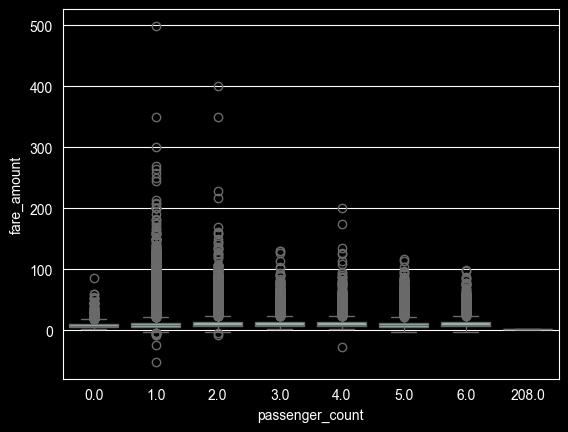

In [16]:
sns.boxplot(data=df,x = 'passenger_count' ,y = 'fare_amount')

In [6]:
df.columns

Index(['fare_amount', 'pickup_datetime', 'pickup_longitude', 'pickup_latitude',
       'dropoff_longitude', 'dropoff_latitude', 'passenger_count'],
      dtype='str')

<Axes: xlabel='hour', ylabel='fare_amount'>

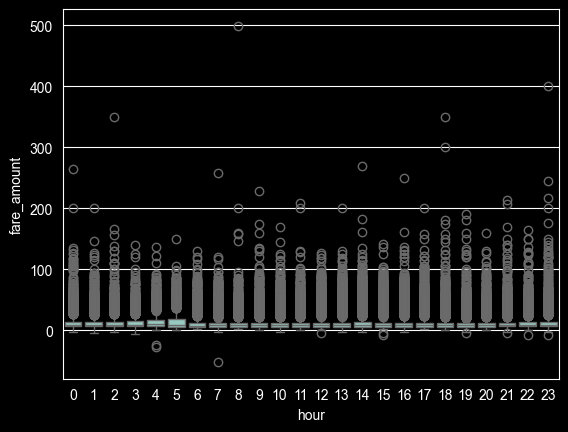

In [23]:
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])
df['hour'] = df['pickup_datetime'].dt.hour
sns.boxplot(df , x='hour' , y = 'fare_amount')

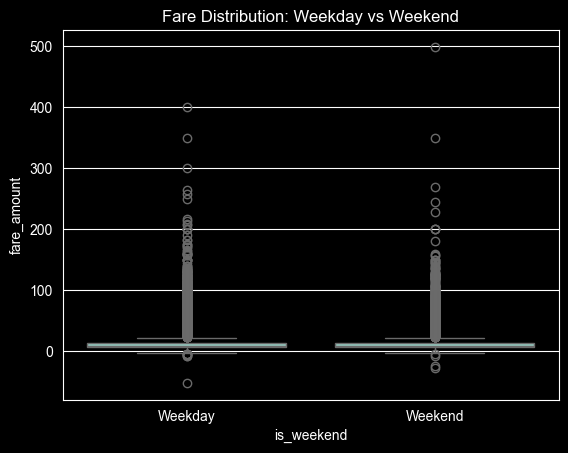

In [19]:
df['day_of_week'] = df['pickup_datetime'].dt.dayofweek  # 0=Monday, 6=Sunday
df['is_weekend'] = df['day_of_week'].isin([5,6])

sns.boxplot(data=df, x='is_weekend', y='fare_amount')
plt.xticks([0,1], ['Weekday','Weekend'])
plt.title("Fare Distribution: Weekday vs Weekend")
plt.show()

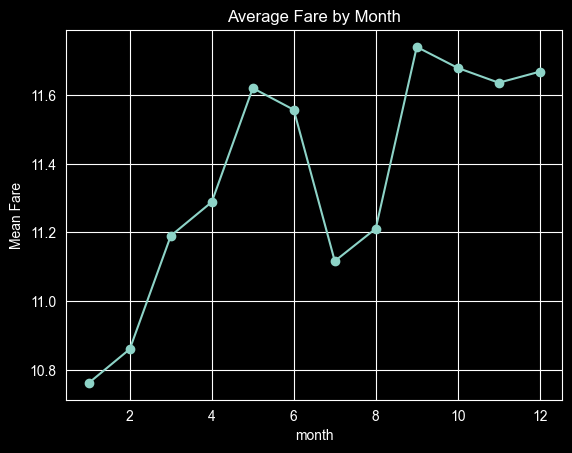

In [20]:
df['month'] = df['pickup_datetime'].dt.month
df.groupby('month')['fare_amount'].mean().plot(kind='line', marker='o')
plt.title("Average Fare by Month")
plt.ylabel("Mean Fare")
plt.show()

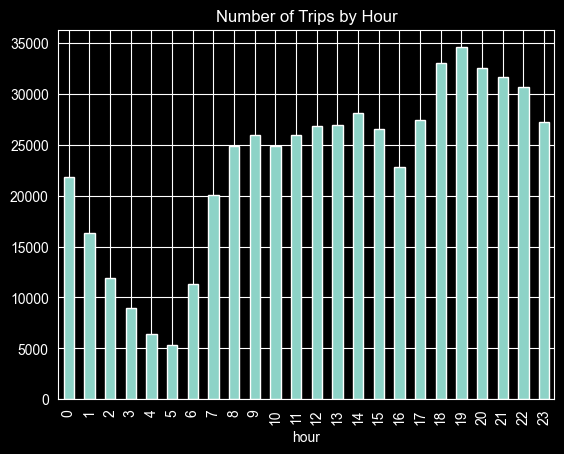

In [22]:
df.groupby('hour').size().plot(kind='bar')
plt.title("Number of Trips by Hour")
plt.show()